# Laboratório 03 — Monitoramento de Data Drift em MLOps

**Objetivo:** manter um modelo de previsão fixo e detectar alterações nas entradas. Dados sintéticos didáticos; nenhum resultado implica degradação real de um sistema de produção. Não usa credenciais ou cloud.

**Pré-requisitos:** Python 3.12; NumPy, pandas, matplotlib.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hashlib import sha256
SEED = 42
rng = np.random.default_rng(SEED)


## 1. Construção da referência e duas janelas
As entradas representam CPU (%) sintética. A referência e a janela de controle têm distribuição semelhante; a janela alterada recebe deslocamento de média.


In [3]:
referencia = np.clip(rng.normal(49, 8, 240), 0, 100)
controle = np.clip(rng.normal(49, 8, 120), 0, 100)
alterada = np.clip(rng.normal(70, 8, 120), 0, 100)
for nome, vetor in [('Referência',referencia),('Controle',controle),('Alterada',alterada)]:
    print(f'{nome}: n={len(vetor)}, média={vetor.mean():.2f}%, desvio={vetor.std():.2f}')


Referência: n=240, média=48.62%, desvio=7.19
Controle: n=120, média=49.53%, desvio=8.18
Alterada: n=120, média=69.91%, desvio=8.09


## 2. Preditor demonstrativo imutável
Aqui usamos a mesma regra de inferência antes e depois do drift. O digest comprova identidade do código da regra neste exercício, não integridade operacional de artefatos Keras/MLflow.


In [4]:
FORMULA = 'memoria_prevista = clip(15 + 0.7 * cpu_pct, 0, 100)'
hash_antes = sha256(FORMULA.encode('utf-8')).hexdigest()
def prever_memoria(cpu_pct):
    return np.clip(15 + 0.7 * np.asarray(cpu_pct), 0, 100)
print('SHA-256 regra:', hash_antes)
print('Predições controle:', np.round(prever_memoria(controle[:3]),2))


SHA-256 regra: df8909dfaa34bd107117782f627bf40737e566885a9d6341d4d7ae46b826b5af
Predições controle: [44.39 48.77 39.46]


## 3. PSI por quantis de referência
PSI = soma((p_atual - p_ref) * ln(p_atual/p_ref)). Usamos dez faixas definidas **somente** na referência, com epsilon para evitar divisão por zero. PSI é uma estatística descritiva sensível às escolhas de faixas e amostragem; não é teste universal de significância.


In [5]:
limites = np.unique(np.quantile(referencia, np.linspace(0, 1, 11)))
limites[0], limites[-1] = -np.inf, np.inf
def calcular_psi(base, atual, limites, eps=1e-6):
    p_ref = np.histogram(base, bins=limites)[0] / len(base)
    p_atual = np.histogram(atual, bins=limites)[0] / len(atual)
    p_ref, p_atual = np.maximum(p_ref,eps), np.maximum(p_atual,eps)
    return float(np.sum((p_atual-p_ref)*np.log(p_atual/p_ref)))
psi_controle = calcular_psi(referencia, controle, limites)
psi_alterada = calcular_psi(referencia, alterada, limites)
print(f'PSI controle: {psi_controle:.3f}')
print(f'PSI alterada: {psi_alterada:.3f}')
assert psi_alterada > psi_controle


PSI controle: 0.102
PSI alterada: 9.070


## 4. Visualização e triagem
Compare a distribuição dos dados e os valores de PSI. Atenção: thresholds operacionais devem ser calibrados com histórico, volumetria e custos de falso alarme.


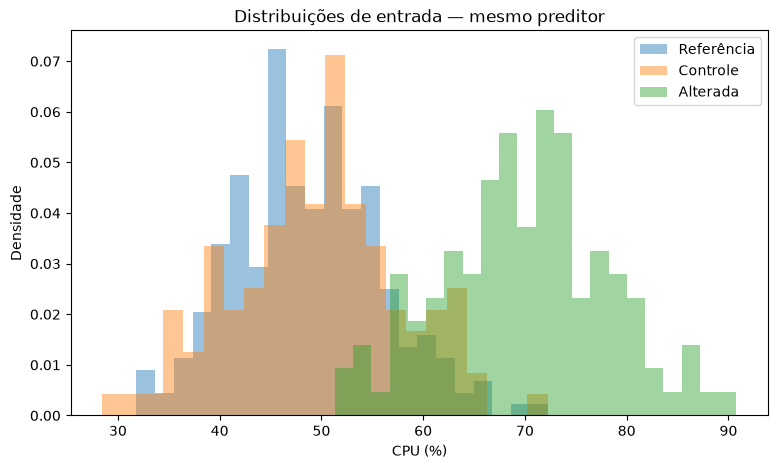

In [6]:
fig, ax = plt.subplots(figsize=(9,5))
ax.hist(referencia, bins=22, alpha=.45, density=True, label='Referência')
ax.hist(controle, bins=22, alpha=.45, density=True, label='Controle')
ax.hist(alterada, bins=22, alpha=.45, density=True, label='Alterada')
ax.set(xlabel='CPU (%)',ylabel='Densidade',title='Distribuições de entrada — mesmo preditor')
ax.legend(); plt.show()


## 5. Validação e interpretação
Sem rótulos reais, não podemos inferir alteração de MAE ou acurácia. Confirmamos somente a alteração das distribuições de entrada. Também não alteramos pesos de modelos treinados em MLflow.


In [7]:
hash_depois = sha256(FORMULA.encode('utf-8')).hexdigest()
assert hash_antes == hash_depois
assert np.all((referencia>=0)&(referencia<=100))
assert np.all((alterada>=0)&(alterada<=100))
print('PASSOU — regra íntegra; drift sintético detectado; não foi medido erro preditivo.')


PASSOU — regra íntegra; drift sintético detectado; não foi medido erro preditivo.


## 6. Próximos passos no projeto completo
Instrumentar logs e métricas para entradas reais autorizadas, definir janela de referência, aplicar PSI por variável, construir alertas auditáveis, incluir ground truth/MAE quando disponível e ligar investigação à esteira DVC → MLflow → Airflow. Não acionar retreinamento automático somente com base em PSI.
